# 📊 Modul 2: Exploratory Data Analysis (EDA) & Business Insights

**Tujuan Modul Ini:**
1. Memeriksa kualitas data (missing values, rentang nilai).
2. Menjawab 4 pertanyaan bisnis utama melalui visualisasi data.
3. Menemukan insight strategis untuk para pemangku kepentingan (*stakeholders*).
4. Menyimpan data bersih & agregasi ke folder `data/processed/` untuk persiapan dashboard.

### 1. Import Library & Muat Data Mentah

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Solusi kompatibilitas Pandas versi baru (2.2+) dengan library visualisasi
try:
    pd._config.config.register_option('mode.use_inf_as_na', False)
except Exception:
    pass

# Setting gaya visualisasi yang bersih dan rapi
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

# Muat dataset mentah hasil ekstraksi Modul 1
data_path = "../data/raw/jakarta_environment_hourly_2024.csv"
df = pd.read_csv(data_path, parse_dates=["time", "date"])

print(f"Dataset berhasil dimuat! Dimensi: {df.shape[0]:,} baris x {df.shape[1]} kolom")
df.head()

Dataset berhasil dimuat! Dimensi: 8,784 baris x 17 kolom


,time,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,us_aqi,temperature_2m,relative_humidity_2m,precipitation,rain,wind_speed_10m,date,hour,day_name,month,is_weekend
0,2024-01-01 00:00:00,135.0,94.5,3010.0,85.2,51.4,158,25.1,97,0.0,0.0,2.2,2024-01-01,0,Monday,1,False
1,2024-01-01 01:00:00,128.1,89.6,3048.0,81.3,47.3,159,24.8,98,0.0,0.0,2.5,2024-01-01,1,Monday,1,False
2,2024-01-01 02:00:00,120.1,84.1,2898.0,73.5,42.3,160,24.4,99,0.0,0.0,1.8,2024-01-01,2,Monday,1,False
3,2024-01-01 03:00:00,106.9,74.7,2650.0,64.0,37.2,160,24.4,99,0.0,0.0,2.2,2024-01-01,3,Monday,1,False
4,2024-01-01 04:00:00,98.5,68.9,2442.0,57.5,35.0,160,24.3,99,0.0,0.0,3.9,2024-01-01,4,Monday,1,False


### 2. Pemeriksaan Kualitas Data (Data Quality Check)
Kita pastikan tidak ada baris yang kosong secara abnormal dan mengecek ringkasan statistik.

In [6]:
# Cek missing values per kolom
null_summary = df.isnull().sum()
print("Jumlah Missing Values per Kolom:")
print(null_summary[null_summary > 0] if null_summary.sum() > 0 else "Tidak ada missing values (Data 100% lengkap)!")

# Ringkasan statistik polusi utama dan cuaca
cols_of_interest = ["pm2_5", "pm10", "us_aqi", "temperature_2m", "precipitation", "wind_speed_10m"]
df[cols_of_interest].describe().round(2)

Jumlah Missing Values per Kolom:
Tidak ada missing values (Data 100% lengkap)!


,pm2_5,pm10,us_aqi,temperature_2m,precipitation,wind_speed_10m
count,8784.00,8784.00,8784.00,8784.00,8784.00,8784.00
mean,62.87,87.53,150.52,27.42,0.28,6.16
std,30.74,43.07,37.99,2.84,1.00,3.60
min,3.40,5.00,55.00,20.10,0.00,0.00
25%,41.00,56.60,133.00,25.10,0.00,3.60
50%,60.10,85.00,157.50,26.70,0.00,5.20
75%,80.30,112.70,171.00,29.60,0.10,8.00
max,217.90,294.30,264.00,37.60,13.60,25.40


---
## 🔍 Analisis 1: Pola Jam (Hourly Pattern)
**Pertanyaan Bisnis**: *Di jam berapa kualitas udara Jakarta paling berisiko bagi warga yang beraktivitas di luar ruangan?*

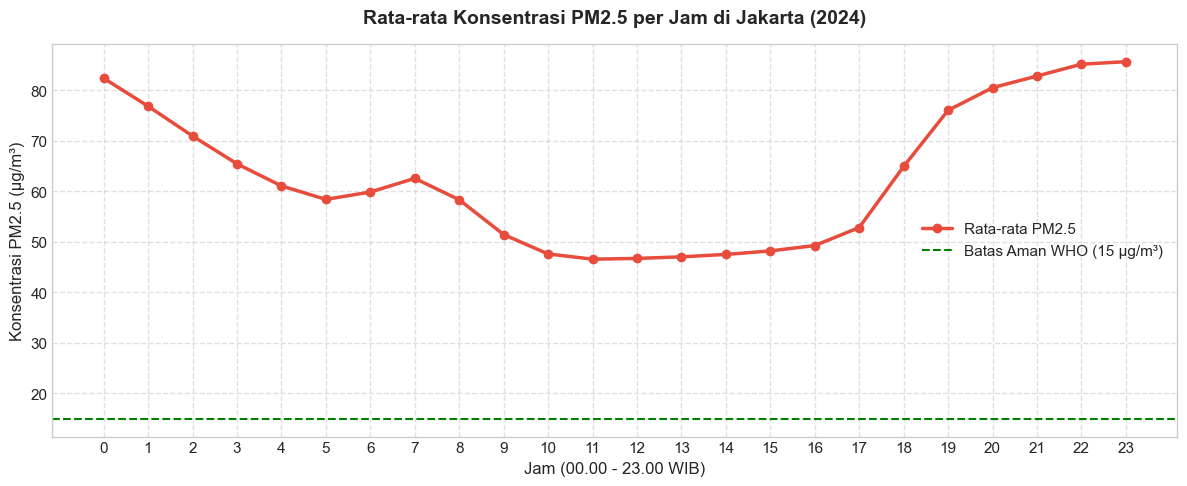

In [7]:
hourly_avg = df.groupby("hour")["pm2_5"].mean().reset_index()

plt.figure(figsize=(12, 5))
# Menggunakan matplotlib murni (bebas error kompatibilitas)
plt.plot(hourly_avg["hour"], hourly_avg["pm2_5"], marker="o", color="#e74c3c", linewidth=2.5, label="Rata-rata PM2.5")

# Garis standar batas aman WHO untuk PM2.5 harian (15 µg/m³)
plt.axhline(15, color="green", linestyle="--", linewidth=1.5, label="Batas Aman WHO (15 µg/m³)")

plt.title("Rata-rata Konsentrasi PM2.5 per Jam di Jakarta (2024)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Jam (00.00 - 23.00 WIB)", fontsize=12)
plt.ylabel("Konsentrasi PM2.5 (µg/m³)", fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---
## 🔍 Analisis 2: Weekend Effect (Hari Kerja vs Akhir Pekan)
**Pertanyaan Bisnis**: *Apakah pengurangan mobilitas perkantoran di akhir pekan menurunkan tingkat polusi secara signifikan?*

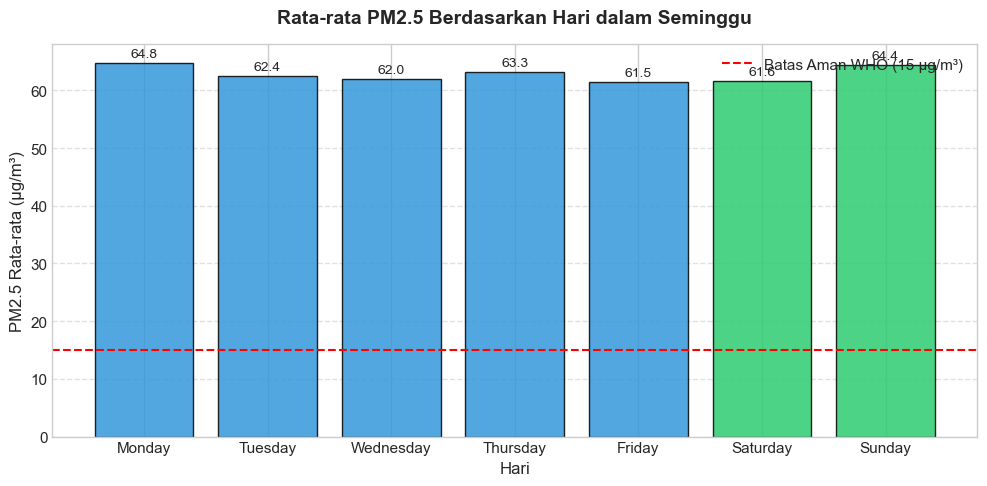

In [8]:
order_days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_avg = df.groupby("day_name")["pm2_5"].mean().reindex(order_days).reset_index()

plt.figure(figsize=(10, 5))
colors = ["#3498db" if day not in ["Saturday", "Sunday"] else "#2ecc71" for day in daily_avg["day_name"]]
bars = plt.bar(daily_avg["day_name"], daily_avg["pm2_5"], color=colors, edgecolor="black", alpha=0.85)

# Tambahkan label nilai di atas tiap batang
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.5, f"{height:.1f}", ha="center", va="bottom", fontsize=10)

plt.title("Rata-rata PM2.5 Berdasarkan Hari dalam Seminggu", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Hari", fontsize=12)
plt.ylabel("PM2.5 Rata-rata (µg/m³)", fontsize=12)
plt.axhline(15, color="red", linestyle="--", linewidth=1.5, label="Batas Aman WHO (15 µg/m³)")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

---
## 🔍 Analisis 3: Pengaruh Hujan (Rain Washing Effect)
**Pertanyaan Bisnis**: *Apakah curah hujan efektif membersihkan polutan udara di Jakarta?*

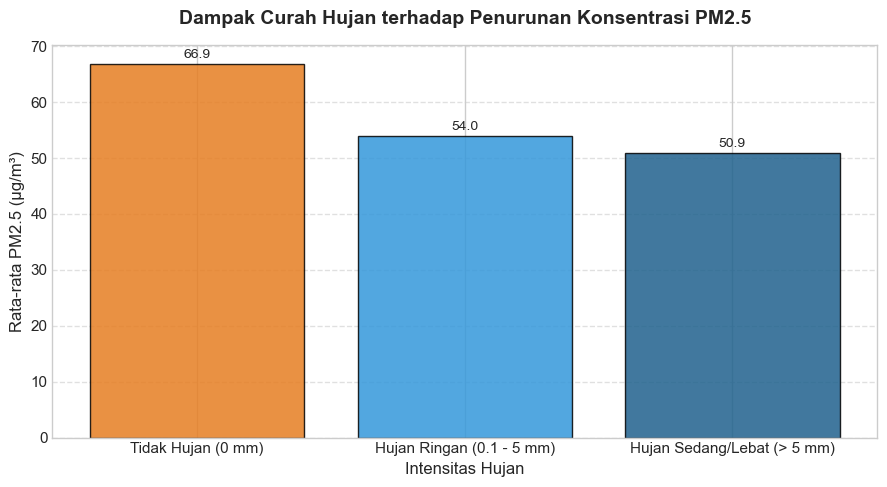

In [9]:
# Kita kategorikan kondisi cuaca: Tidak Hujan vs Hujan Ringan vs Hujan Lebat
def categorize_rain(val):
    if val == 0:
        return "Tidak Hujan (0 mm)"
    elif val < 5:
        return "Hujan Ringan (0.1 - 5 mm)"
    else:
        return "Hujan Sedang/Lebat (> 5 mm)"

df["rain_category"] = df["precipitation"].apply(categorize_rain)
rain_order = ["Tidak Hujan (0 mm)", "Hujan Ringan (0.1 - 5 mm)", "Hujan Sedang/Lebat (> 5 mm)"]
rain_impact = df.groupby("rain_category")["pm2_5"].mean().reindex(rain_order).reset_index()

plt.figure(figsize=(9, 5))
bars = plt.bar(rain_impact["rain_category"], rain_impact["pm2_5"], color=["#e67e22", "#3498db", "#1f618d"], edgecolor="black", alpha=0.85)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.5, f"{height:.1f}", ha="center", va="bottom", fontsize=10)

plt.title("Dampak Curah Hujan terhadap Penurunan Konsentrasi PM2.5", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Intensitas Hujan", fontsize=12)
plt.ylabel("Rata-rata PM2.5 (µg/m³)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

---
## 🔍 Analisis 4: Tren Musiman (Kemarau vs Hujan Sepanjang 2024)
**Pertanyaan Bisnis**: *Bulan-bulan apa yang paling kritis dan membutuhkan intervensi kebijakan ketat?*

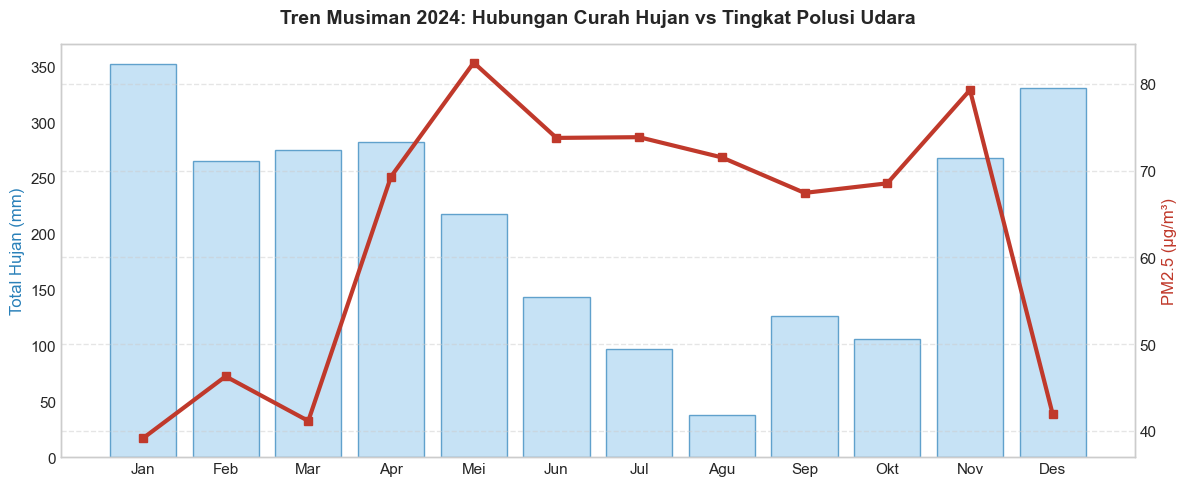

In [10]:
month_map = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
    7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"
}
monthly = df.groupby("month").agg({
    "pm2_5": "mean",
    "precipitation": "sum"
}).reset_index()
monthly["month_name"] = monthly["month"].map(month_map)

fig, ax1 = plt.subplots(figsize=(12, 5))

# Bar chart untuk curah hujan
ax1.bar(monthly["month_name"], monthly["precipitation"], color="#aed6f1", edgecolor="#2980b9", alpha=0.7, label="Total Curah Hujan (mm)")
ax1.set_ylabel("Total Hujan (mm)", color="#2980b9", fontsize=12)
ax1.grid(False)

# Line chart untuk PM2.5
ax2 = ax1.twinx()
ax2.plot(monthly["month_name"], monthly["pm2_5"], color="#c0392b", marker="s", linewidth=3, label="Rata-rata PM2.5 (µg/m³)")
ax2.set_ylabel("PM2.5 (µg/m³)", color="#c0392b", fontsize=12)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.title("Tren Musiman 2024: Hubungan Curah Hujan vs Tingkat Polusi Udara", fontsize=14, fontweight="bold", pad=15)
fig.tight_layout()
plt.show()

---
## 💾 3. Agregasi Harian & Simpan Data Bersih
Untuk visualisasi di Power BI / Tableau nanti, kita butuh data agregasi harian yang ringkas beserta kategori kualitas udara resmi (Good, Moderate, Unhealthy).

In [11]:
# Agregasi per tanggal
daily_summary = df.groupby("date").agg({
    "pm2_5": "mean",
    "pm10": "mean",
    "us_aqi": "max",             # AQI tertinggi dalam 1 hari
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "precipitation": "sum",       # Total curah hujan harian
    "wind_speed_10m": "mean"
}).reset_index()

# Klasifikasi Standar Kategori AQI AS (US EPA Standard)
def classify_aqi(aqi):
    if aqi <= 50:
        return "Baik (Good)"
    elif aqi <= 100:
        return "Sedang (Moderate)"
    elif aqi <= 150:
        return "Tidak Sehat bagi Kelompok Sensitif"
    elif aqi <= 200:
        return "Tidak Sehat (Unhealthy)"
    else:
        return "Sangat Tidak Sehat / Berbahaya"

daily_summary["aqi_category"] = daily_summary["us_aqi"].apply(classify_aqi)

# Simpan ke processed
processed_path = "../data/processed/jakarta_daily_summary_2024.csv"
daily_summary.to_csv(processed_path, index=False)
print(f"Data agregasi harian berhasil disimpan ke: {processed_path}")
print(daily_summary["aqi_category"].value_counts())
daily_summary.head()

Data agregasi harian berhasil disimpan ke: ../data/processed/jakarta_daily_summary_2024.csv
aqi_category
Sangat Tidak Sehat / Berbahaya        163
Tidak Sehat (Unhealthy)               118
Tidak Sehat bagi Kelompok Sensitif     46
Sedang (Moderate)                      39
Name: count, dtype: int64


,date,pm2_5,pm10,us_aqi,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,aqi_category
0,2024-01-01,69.270833,99.570833,223,26.829167,87.625000,11.0,4.533333,Sangat Tidak Sehat / Berbahaya
1,2024-01-02,56.416667,80.866667,179,27.400000,84.666667,8.4,4.904167,Tidak Sehat (Unhealthy)
2,2024-01-03,40.066667,57.445833,151,25.783333,91.041667,29.5,5.616667,Tidak Sehat (Unhealthy)
3,2024-01-04,49.662500,71.470833,134,25.241667,92.875000,59.8,6.691667,Tidak Sehat bagi Kelompok Sensitif
4,2024-01-05,49.258333,70.529167,147,26.679167,84.125000,15.9,5.529167,Tidak Sehat bagi Kelompok Sensitif
